In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Any, Callable
import yfinance as yf

In [6]:
data = pd.read_excel("close_prices_portfolio.ods", engine="odf", index_col = 'Date', parse_dates = True)

In [12]:
data_log = pd.DataFrame(data.values, columns = data.columns, index = data.index)
data_log.index.name = "Date"
data_log[data_log.columns[:-1]] = np.log(data_log[data_log.columns[:-1]])
data_log['USD/EUR'] = np.exp(data_log['USD/EUR'])

In [44]:
data_log

,S&P 500,DAX,AEX,USD/EUR,S&P 500 in EUR,Euribor rates
Date,,,,,,
2012-04-10,7.214203,8.795799,5.723291,1.311131,7.485093,0.764
2012-04-11,7.221624,8.806084,5.729353,1.307360,7.489634,0.760
2012-04-12,7.235309,8.816296,5.739407,1.311992,7.506856,0.757
2012-04-13,7.222756,8.792383,5.723977,1.318913,7.499564,0.753
2012-04-16,7.222252,8.798634,5.723650,1.305653,7.488956,0.750
...,...,...,...,...,...,...
2022-04-04,8.430031,9.583156,6.603673,1.104728,8.529630,-0.547
2022-04-05,8.417399,9.576674,6.601257,1.097586,8.510513,-0.551
2022-04-06,8.407635,9.557589,6.578793,1.090643,8.494403,-0.548


In [45]:
def group4_loss_operator(log_data):
    rates = log_data['Euribor rates']
    rates_risk = 0.4 * (0.0002 + 0.25 * rates.diff().fillna(0))
    other_risk = 0.2 * log_data[['DAX','AEX','S&P 500 in EUR']].diff().fillna(0)
    ind_loss = pd.DataFrame(data = log_data[['S&P 500 in EUR', 'DAX', 'AEX', 'Euribor rates']].diff().fillna(0).values,
                             index = log_data.index, columns = ['S&P 500', 'DAX', 'AEX', 'EURIBOR'])
    ind_loss['EURIBOR'] = rates_risk
    return -1 * (other_risk.sum(axis = 1) + rates_risk), -1 * ind_loss

<Axes: xlabel='Date'>

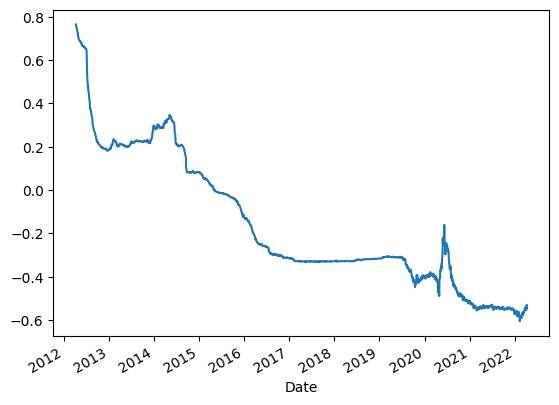

In [46]:
data_log['Euribor rates'].plot()

<Axes: xlabel='Date'>

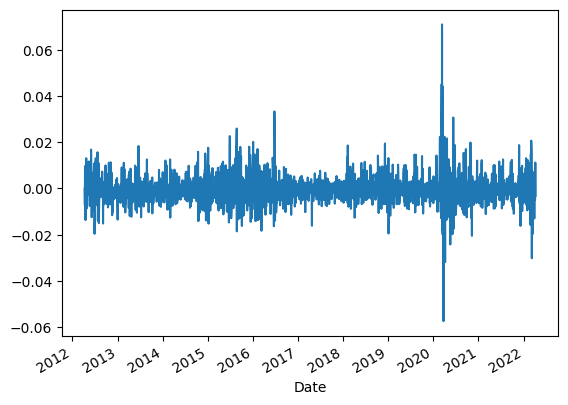

In [47]:
loss, ind_loss = group4_loss_operator(log_data=data_log)
loss.plot()

<Axes: xlabel='Date'>

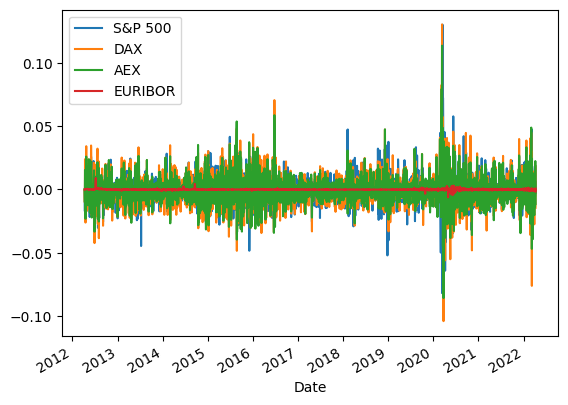

In [48]:
ind_loss.plot()

In [59]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        if t % 365 == 0:
            if t != 0:
                omega = np.var(x[t - 365: t]) * (1 - alpha - beta)
        sig[t+1] = omega + alpha *  (x[t]**2) + beta * sig[t]

    return sig ** .5

def GARCH_portfolio_variance(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr().fillna(0)
    n: int = CM.shape[0]
    weights = np.array(weights)
    W = weights.reshape((n, 1)) * weights.reshape((1,len(weights)))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .2, 0.78
        omega = 0#np.var(x[:365]) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
      
    vol = []
    
    Sigm = vol_df.values
    for row in Sigm:
        # Variance as outer product of the weights with the covariance
        vol.append(row @ CMU @ row)
    return np.array(vol) ** .5

def GARCH_VaR(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)


def devol(data: pd.DataFrame, pf_loss, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    return pf_loss / portfolio_VaR.Vol

In [60]:
def Var_Cov_ES(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    match dist:
        case stats.norm:
            q: float = stats.norm.ppf(alpha)
            p: float = stats.norm.pdf(q)
            return Vol * p / (1 - alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.ppf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return Vol * ((df + (q ** 2)) / (df - 1)) * p / (1 - alpha)
        case _:
            raise NotImplementedError() 

In [67]:
GARCH = GARCH_portfolio_variance(ind_loss, weights = [.2, .2, .2, .4])
VaR_GARCH1 = GARCH_VaR(GARCH, .975, stats.norm.ppf)
ES_GARCH1 = Var_Cov_ES(GARCH, .975, stats.norm)

VaR_GARCH2 = GARCH_VaR(GARCH, .99, stats.norm.ppf)
ES_GARCH2 = Var_Cov_ES(GARCH, .99, stats.norm)

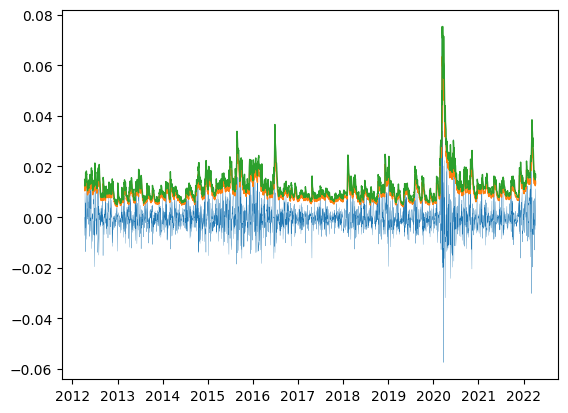

In [68]:
plt.plot(loss, lw = .2)
plt.plot(loss.index, VaR_GARCH1, lw = 1)
plt.plot(loss.index, VaR_GARCH2, lw = 1)

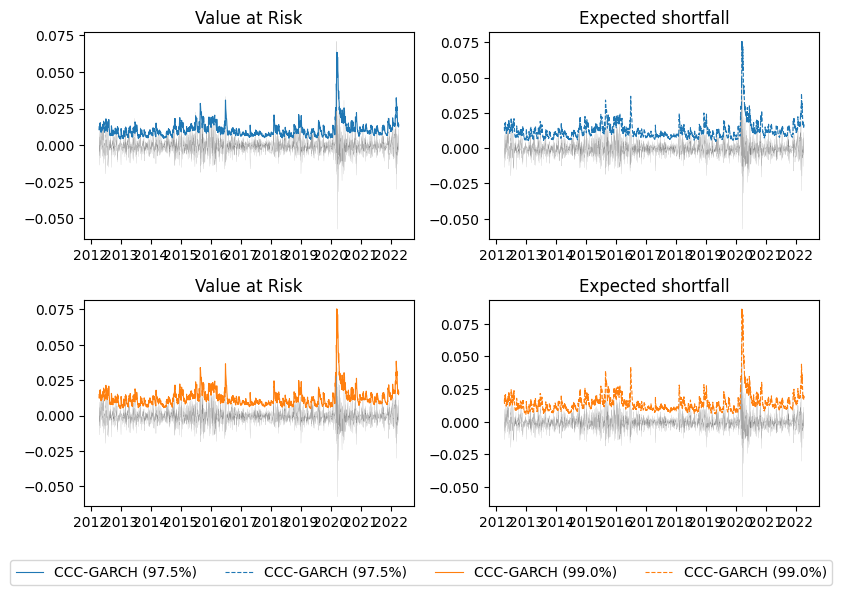

In [76]:
fig, axs = plt.subplots(2, 2, figsize = (8.2543, 8.2543 / 1.5))
# fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[0,1].set_title('Expected shortfall')
axs[0,1].plot(loss, lw = .1, c = 'black', alpha = .5)
axs[0,1].plot(loss.index, ES_GARCH1, label = 'CCC-GARCH (97.5%)', lw = .8, c = 'C0', ls = 'dashed')

axs[0,0].set_title('Value at Risk')
axs[0,0].plot(loss, lw = .1, c = 'black', alpha = .5)
axs[0,0].plot(loss.index, VaR_GARCH1, label = 'CCC-GARCH (97.5%)', c = 'C0', lw = .8)
# axs[0,0].plot(VaR_ES_Historic_Simulation.VaR, label = 'Historic Simulation', lw = .8, c = 'C1')

axs[1,1].set_title('Expected shortfall')
axs[1,1].plot(loss, lw = .1, c = 'black', alpha = .5)
axs[1,1].plot(loss.index, ES_GARCH2, label = 'CCC-GARCH (99.0%)', lw = .8, c = 'C1', ls = 'dashed')

axs[1,0].set_title('Value at Risk')
axs[1,0].plot(loss, lw = .1, c = 'black', alpha = .5)
axs[1,0].plot(loss.index, VaR_GARCH2, label = 'CCC-GARCH (99.0%)', c = 'C1', lw = .8)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes]#[:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
fig.tight_layout()
plt.savefig('garch_a2.pdf', bbox_inches = 'tight')
plt.show()

In [77]:
def VaR_violations(loss: pd.DataFrame, VaR: object) -> ...:
    try: 
        vv = np.where(loss >= VaR, 1, 0)
        vv = pd.DataFrame(vv, index = loss.index, columns = ['violation dates'])
    except: 
        vv = np.where(loss.loc[VaR.index] >= VaR, 1, 0)
        vv = pd.DataFrame(vv, index = VaR.index, columns = ['violation dates'])
    return vv[vv['violation dates'] == 1].index, vv

In [90]:
dates1, violations1 = VaR_violations(loss, VaR_GARCH1)
dates2, violations2 = VaR_violations(loss, VaR_GARCH2)

In [94]:
print(violations1.mean(), violations2.mean())

violation dates    0.042097
dtype: float64 violation dates    0.026211
dtype: float64


In [91]:
import scipy 
def bt(data,p):
    n = len(data)
    k = int(np.sum(data))
    return scipy.stats.binomtest(k = k, n = n, p = p)

In [96]:
34/2330

0.014592274678111588

In [92]:
bt(violations1, .025)

BinomTestResult(k=106, n=2518, alternative='two-sided', statistic=0.04209690230341541, pvalue=5.28726527406071e-07)

In [93]:
bt(violations2, .01)

BinomTestResult(k=66, n=2518, alternative='two-sided', statistic=0.026211278792692614, pvalue=7.183921395539815e-12)

In [97]:
def lr_bt(hits, alpha):
        """Likelihood ratio framework of Christoffersen (1998)"""
        tr = hits[1:] - hits[:-1]  # Sequence to find transitions

        # Transitions: nij denotes state i is followed by state j nij times
        n01, n10 = (tr == 1).sum(), (tr == -1).sum()
        n11, n00 = (hits[1:][tr == 0] == 1).sum(), (hits[1:][tr == 0] == 0).sum()

        # Times in the states
        n0, n1 = n01 + n00, n10 + n11
        n = n0 + n1

        # Probabilities of the transitions from one state to another
        p01, p11 = n01 / (n00 + n01), n11 / (n11 + n10)
        p = n1 / n

        if n1 > 0:
            # Unconditional Coverage
            uc_h0 = n0 * np.log(1 - alpha) + n1 * np.log(alpha)
            uc_h1 = n0 * np.log(1 - p) + n1 * np.log(p)
            uc = -2 * (uc_h0 - uc_h1)

            # Independence
            ind_h0 = (n00 + n01) * np.log(1 - p) + (n01 + n11) * np.log(p)
            ind_h1 = n00 * np.log(1 - p01) + n01 * np.log(p01) + n10 * np.log(1 - p11)
            if p11 > 0:
                ind_h1 += n11 * np.log(p11)
            ind = -2 * (ind_h0 - ind_h1)

            # Conditional coverage
            cc = uc + ind

            # Stack results
            df = pd.concat([pd.Series([uc, ind, cc]),
                            pd.Series([1 - stats.chi2.cdf(uc, 1),
                                       1 - stats.chi2.cdf(ind, 1),
                                       1 - stats.chi2.cdf(cc, 2)])], axis=1)
        else:
            df = pd.DataFrame(np.zeros((3, 2))).replace(0, np.nan)

        # Assign names
        df.columns = ["Statistic", "p-value"]
        df.index = ["Unconditional", "Independence", "Conditional"]

        return df

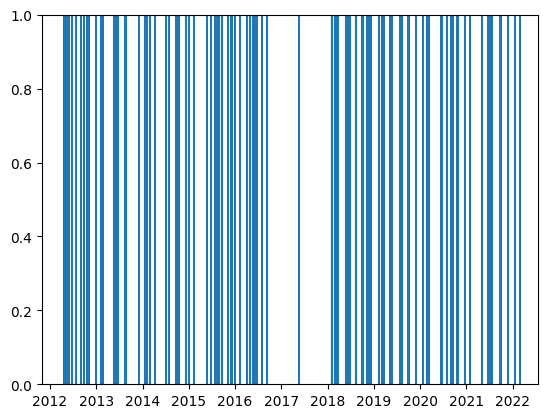

In [100]:
for _ in dates1: plt.axvline(_)

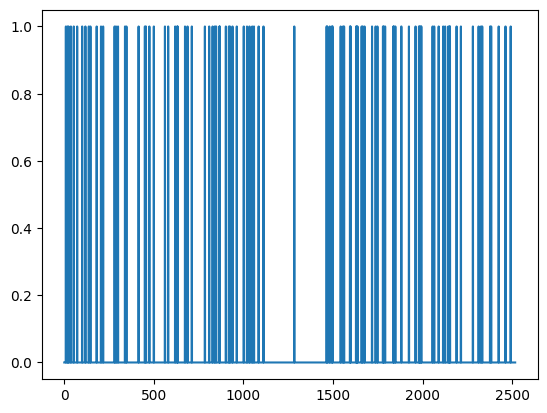

In [106]:
plt.plot(violations1.values)

In [126]:
print(lr_bt(violations1.values, .05))

               Statistic   p-value
Unconditional   3.474185  0.062333
Independence    0.054331  0.815692
Conditional     3.528515  0.171314


In [127]:
print(lr_bt(violations2.values, 0.05))

               Statistic       p-value
Unconditional  35.988140  1.985222e-09
Independence    0.042198  8.372434e-01
Conditional    36.030337  1.500070e-08
